# STAGE 1 & STAGE 2 — Kiểm kê dữ liệu & Hiểu cấu trúc chuỗi thời gian

**Đề tài:** Mô hình hóa mức độ phơi nhiễm chuỗi lạnh & dự đoán RSL của xoài xuất khẩu đường dài (Việt Nam → Pháp).

Notebook này thực hiện:
- **STAGE 1 — Data Inventory:** liệt kê toàn bộ file (raw logs cảm biến, đo chất lượng, metadata chặng vận chuyển, hình ảnh), xác định cấu trúc thư mục, xây dựng **Data Dictionary**, và xác định **phân cấp thực thể** `Shipment_ID → Pallet_ID → Box_ID → Mango_ID → Sensor_ID`.
- **STAGE 2 — Time-Series Structure:** tái dựng **timeline chuỗi lạnh** (Step 0 → Step 10), **kiểm chuẩn timestamps** (múi giờ, sampling step, trùng lặp/gaps) và **ánh xạ Sensor ↔ Thùng hàng (kênh nhiệt độ quả — **vị trí cảm biến chưa xác minh** — vs. không khí thùng vs. khoang ngoài).

---
# 📖 TỪ ĐIỂN THUẬT NGỮ (GLOSSARY) — Dành cho người mới explore data

> Đọc mục này **trước** khi chạy các cell bên dưới. Mỗi thuật ngữ được giải thích theo 3 lớp:
> **(1) Nghĩa thông thường → (2) Nghĩa trong dataset cụ thể này → (3) Ví dụ số liệu thật.**

---

## A. Thuật ngữ về THIẾT BỊ & ĐO LƯỜNG

### 1. iButton (DS1922L / DS1923)
- **Nghĩa chung**: một "nút" ghi dữ liệu (data logger) hình đồng xu nhỏ của hãng Dallas/Maxim, tự ghi nhiệt độ vào bộ nhớ trong theo chu kỳ, không cần dây.
- **Trong dataset**: đây chính là các **sensor** được thả *vào trong thùng* cùng xoài. Có 62 cái cho 31 thùng.
  - `DS1922L` = bản chỉ đo **nhiệt độ** → file tên kết thúc bằng `_Temp`.
  - `DS1923` = bản đo **nhiệt độ + độ ẩm** → file tên kết thúc bằng `_Temp_Hum`.
- **Điểm mấu chốt khi explore**: mỗi file log = **một iButton tại một vị trí**, không phải một "cảm biến" trừu tượng.

### 2. Data logger / Sensor_ID
- **Sensor_ID**: mã định danh duy nhất của từng thiết bị đo (thường nằm ở dòng header của file iButton gốc). Khi merge nhiều chặng (`00_All_Recording...`), Sensor_ID cho biết các file Step rời rạc có phải **cùng một con cảm biến** hay không.

### 3. Sampling step (bước nhảy thời gian / chu kỳ lấy mẫu)
- Chuỗi thời gian cách đều nhau bao lâu thì ghi 1 điểm. Dataset này = **5 phút** (README xác nhận, notebook kiểm chứng lại trên cả 342 file).
- Nghĩa là 1 giờ có 12 dòng dữ liệu; 1 ngày = 288 dòng. Dùng để tính kỳ vọng số dòng và phát hiện gap.

### 4. Resolution (độ phân giải) vs Uncertainty (độ bất định ±)
- **Resolution 0.5°C**: giá trị nhỏ nhất thiết bị *phân biệt được* → số liệu nhiệt độ sẽ **nhảy bậc 0.5** (31.5, 32.0... chứ không bao giờ ra 31.7). Đừng nhầm bước nhảy 0.5°C này với "gap" hay "bất thường".
- **Uncertainty ±0.6°C (k=2)**: khoảng tin cậy ~95% quanh giá trị đọc. Nghĩa vật lý: nếu log ghi `31.6`, nhiệt độ *thực* nằm đâu đó trong `[31.0 ; 32.2]`.
  - Hệ quả khi explore: chênh lệch giữa 2 cảm biến < 0.6–1.2°C **chưa chắc là khác biệt thật** — phải so với độ bất định trước khi kết luận.
- **k = 2**: hệ số mở rộng (coverage factor) trong đo lường học, k=2 ≈ mức tin cậy 95%.

### 5. Tiếp xúc (contact) vs Không khí (air) vs Khoang ngoài
- `T_mangoes`: cột "nhiệt độ xoài" — README gốc chỉ ghi *"mango temperature"*, **không mô tả vị trí đặt cảm biến**. Chưa xác minh (unverified): có thể là áp bề mặt vỏ, lồng trong mô quả, hoặc đặt giữa các quả trong thùng. KHÔNG được gọi là "core temperature" (nhiệt tâm) hay "surface temperature" cho tới khi cộng sự INRAE xác nhận cách bố trí 62 iButton.
- `T_Air`: iButton đo **không khí lồng trong thùng carton**.
- Khoang ngoài: nhiệt độ **bên ngoài thùng** (kho lạnh INRAE 16°C/21°C, sàn bay...) — môi trường lớn.

---

## B. Thuật ngữ về CHUỖI LẠNH (COLD CHAIN)

### 6. Cold chain (chuỗi lạnh)
Toàn bộ hành trình giữ lạnh từ vườn → người ăn. Mỗi "khâu" là một **Step** (0→10): Packing House → Tiền lạnh → Xe → Sân bay đi → Bay → Sân bay đến → Lưu kho...
Mục tiêu đề tài: tìm khâu nào để nhiệt độ "trượt" khỏi dải an toàn (>~8–10°C gây hỏng/qu chín nhanh).

### 7. ULD (Unit Load Device)
- Container/kiện chuẩn dùng chất hàng lên máy bay thân rộng. README: **1 ULD chứa 148 thùng carton**, trong đó **31 thùng được gắn cảm biến** đặt ở các vị trí khác nhau.
- Vì vậy Box_ID `X_Y_Z` mô tả **vị trí hình học trong ULD** (xem mục C).

### 8. Pre-cooling (tiền lạnh, Step 1 – Cold Storage)
Làm lạnh nhanh ngay sau thu hoạch để "rút" nhiệt đồng ruộng (field heat) khỏi quả trước khi xếp lên máy bay. Step dài nhất (~20h) trong timeline.

### 9. Chilling injury (CI – tổn thương lạnh)
Hỏng do bảo quản quá lạnh (<~5–8°C với cây nhiệt đới như xoài): rám vỏ, chín ép, vị lạ. Là lý do thí nghiệm chọn 2 mức lưu kho **16°C vs 21°C** (an toàn, gần ngưỡng CI) để đối chiếu tốc độ suy giảm phẩm chất.

---

## C. Thuật ngữ về CẤU TRÚC THỰC THỂ

### 10. Box_ID dạng `X_Y_Z` (ví dụ `1_1_1`, `3_3_12`)
Không phải "tầng/vị trí" tùy tiện — **đây là tọa độ pallet trong ULD** (được cộng sự Pháp xác nhận trong README/script):
```
X = hàng dọc (row)      : 1 … 4   (1 = sát cửa/lối đi ←→ 4 = sâu trong ULD)
Y = hàng ngang (column) : 1 … 4   (trái ↔ phải)
Z = cột đứng (stack)    : 1 … 12  (1 = đáy ←→ 12 = đỉnh)
```
- 4×4×12 = 192 ô khả dĩ, thực tế 148 thùng, 31 thùng có cảm biến.
- **Ý nghĩa khi explore**: X,Y,Z quyết định thùng chịu gió lạnh/gió nóng thế nào → vì sao README nói có "10 box đỉnh, 9 box giữa chiều cao, 5 box đáy..." (chọn theo vị trí cực đoan để bắt gradient nhiệt).
- ⚠️ Đừng nhầm `X_Y_Z` trong file sensor (vị trí ULD) với số `1_/2_/3_/4_` đầu file quality (**configuration** — xem mục E).

### 11. Mango_ID dạng `BOX_NAME` ví dụ `1_1_1/1-1A`
Chuỗi ghép trong file màu/khối lượng, tách được thành 3 phần:
```
1_1_1   /   1     -   1A
 │        │         └─ vị trí đo trên quả (1..6) + mã lô ảnh
 │        └─ quả thứ # trong thùng (1..14)
 └─ Box_ID (thùng)
```
File weight dùng `M_1_1_1/7` = khối lượng **quả số 7 trong thùng (1,1,1)**. Mỗi thùng 14 quả, chia 2 nhóm 7 bởi một vách ngăn (partition).

### 12. Entity hierarchy (phân cấp thực thể)
Sơ đồ "trong-này-chứa-trong-kia": Shipment → Pallet/ULD → Box → Mango → Sensor. Mọi bảng khi explore nên giữ đủ khóa ngoại này (dạng `box`, `mango`) để group-by/pivot được mà không gộp nhầm.

---

## D. Thuật ngữ về PHẨM CHẤT XOÀI (QUALITY ATTRIBUTES)

### 13. Khối lượng M (Mass) — đơn vị gam
Xoài mất nước → hao hụt khối lượng (weight loss). So sánh M_D15/M_D0 (% thất thoát) là chỉ số thương mại quan trọng. Cân KERN ±0.008g — rất nhỏ so với quả ~350g, tức nhiễu cân bỏ qua được.

### 14. Màu CIE L\*a\*b\* (spectrophotometer CM-700d)
Không gian màu chuẩn quốc tế, 3 trục độc lập:
| Trục | Nghĩa | Xoài chín thì... |
|---|---|---|
| **L\*** | Độ sáng, 0 (đen) → 100 (trắng) | thay đổi nhẹ |
| **a\*** | **−a = xanh lá**, **+a = đỏ/đỏ cam** | tăng (lá → sắc đỏ/cam) |
| **b\*** | **−b = xanh dương**, **+b = vàng** | **tăng mạnh** (xoài chuyển vàng) |
- Ví dụ thật (file color): `1_1_1/1-1A`: b\* = 34.09 (D0) → 51.55 (D9) → 46.85 (D15): quả vàng dần rồi hơi chững — tín hiệu chín.
- Đo **6 vị trí/quả** (các后缀 `-1A ... -6F`), trung bình 3 lần đo liên tiếp.
- Tổng hợp thành chỉ số vàng hóa thường dùng: `Chromaticity = √(a*² + b*²)` hoặc `hue angle = atan2(b*, a*)`.

### 15. pH
Độ acid (thang log, 0–14,越低 càng chua). Xoài chín: acid hữu cơ giảm → **pH tăng nhẹ** (≈4.0 → 4.5+). Máy Starter 300 ±0.03.

### 16. TSS / °Brix (Total Soluble Solids)
Tổng chất rắn hòa tan (chủ yếu đường) — khúc xạ kế PAL-BrixAcid1 ±0.4°Bx. Xoài chín: tinh bột → đường → **TSS tăng** (≈11 → 15°Bx). Kết hợp pH → tỷ lệ maturité `TSS/pH` càng cao càng ngọt/chín.

### 17. D0, D3, D6, D9, D12, D15 ("ngày")
Ngày lấy mẫu **sau khi đến phòng lab** (D0 = 18/04/2023, D15 = 05/05/2023), đo định kỳ 3 ngày/lần trong 15 ngày lưu kho. Đây là chuỗi thời gian **rời, thưa** (6 mốc) — khác hẳn chuỗi sensor dày 5 phút. Trong file color, cột `L_D3, a_D3, b_D3...` = giá trị tại từng ngày.

---

## E. Thuật ngữ về TỔ CHỨC FILE & THÍ NGHIỆM

### 18. `src` vs `res` (source vs result)
- `NN_src_subset_dataset_*` = **dữ liệu thô** (raw values, txt từng điểm đo).
- `NN_res_subset_dataset_*` = **dữ liệu đã xử lý** (min/max/trung bình/std + đồ thị) do script R sinh ra.
- Explore nên luôn bắt đầu từ `src`; `res` dùng để đối chiếu kết quả tính toán của mình có khớp nhóm nghiên cứu gốc không.

### 19. Configuration 1_ / 2_ / 3_ / 4_ (thiết kế thí nghiệm)
4 cách *chọn mẫu* khi đo phẩm chất (khác bản chất, đừng trộn khi phân tích!):
| Prefix | Cách chọn | Nhiệt độ lưu kho |
|---|---|---|
| `1_` | thùng ở **vị trí cực đoan** trong ULD (đỉnh/đáy/góc) | 21°C |
| `2_` | thùng **ngẫu nhiên** ở vị trí không cực đoan | 21°C |
| `3_` | **quả ngẫu nhiên** bất kỳ, không quan tâm vị trí thùng | 21°C |
| `4_` | quả ngẫu nhiên bất kỳ | 16°C |
→ Chỉ `4_` là nhánh 16°C; `1_,2_,3_` đều 21°C. Muốn so sánh 2 nhiệt độ: dùng `3_` vs `4_` (cùng kiểu random) để công bằng.

### 20. `SR` (folder 11/12) = Storage Room
3 file log **toàn trình** của 3 iButton đặt **trong kho lạnh INRAE** (không gắn thùng) — đại diện "khoang ngoài", 2 chế độ 16°C & 21°C.

### 21. Metadata
"Dữ liệu về dữ liệu": tên file encode Step+vị trí, README encode thiết bị/sai số, script R encode quy trình. Notebook Stage 1 chủ yếu là **giải metadata thành cột dataframe**.

### 22. Timezone / UTC / Local time
Timestamp trong file là **giờ địa phương nơi đặt cảm biến** (Việt Nam/Thái Lan: Asia/Ho_Chi_Minh ~ ICT; Pháp: Europe/Paris CET/CEST) nhưng **không ghi chú thích timezone trong file** → cạm bẫy số 1 khi nối các chặng. Chuẩn xử lý: localize đúng múi giờ từng chặng → convert all to UTC → mới được tính gap/duration. (Notebook cell 2.2 làm việc này.)

### 23. Gap / Duplicate / Backward jump
- **Gap**: khoảng trống > 1 bước mẫu (ở đây > 10 phút = bất thường; thường do rút/iButton nghỉ).
- **Duplicate**: 2 dòng cùng timestamp (lỗi đọc/xuất file).
- **Backward jump**: timestamp lùi (đổi đồng hồ, đổi TZ, hoặc gộp file sai).
Ba loại này là "smell test" đầu tiên của mọi chuỗi thời gian.

### 24. Tương quan trễ (lagged cross-correlation)
Nếu cột T_mangoes phản ánh nhiệt KHỐI QUẢ (giả định — vị trí cảm biến chưa xác minh, xem mục 2.3), nó không phản ứng tức thì với T_air vì khối quả có **nhiệt dung lớn** → đường cong T_mangoes là T_Air bị "làm trơn + trễ". Phân tích tương quan theo lag (5/10/15/30 phút) tìm lag mà hệ số tương quan cực đại ⇒ ước lượng thời hằng nhiệt (thermal time constant, τ). Lưu ý: dấu hiệu trễ dương cũng xuất hiện nếu cảm biến nằm ở BỀ MẶT vỏ quả, nên kết quả lag chỉ dùng để mô tả hành vi chuỗi, CHƯA đủ để suy ngược vị trí cảm biến.

### 25. Symlink (liên kết mềm)
"Shortcut" tới file/thư mục gốc — cấu trúc chuẩn hóa `data/raw/sensor/`, `data/raw/quality/` tạo bằng symlink để **không nhân bản dữ liệu**; khi đếm file nhớ lọc trùng (`resolve()`), nếu không số liệu sẽ gấp đôi.

### 26. Regex (biểu thức chính quy)
Ngôn ngữ mô tả khuôn mẫu chuỗi, dùng để "bẻ khóa" tên file: ví dụ `^(\d+)_(\w+)_([1-4]_[1-4]_\d{1,2})_Temp(_Hum)?\.txt$` tách đồng thời Step, StepName, Box_ID, loại kênh của 342 file cùng lúc.

---

## F. SỔ TAY EXPLOR nhanh (thứ tự nên đi)

1. Mở `data/raw/0_README.txt` — mọi câu trả lời nghiệp vụ nằm đây.
2. Cell 1.1.b: chạy regex → thấy ngay 100% tên file decode được.
3. Vẽ 1 file sensor (`0_Packing_House_1_1_1_Temp_Hum.txt`): 3 đường T_mangoes/T_Air/RH_Air, để ý bậc nhảy 0.5°C.
4. Nối 11 chặng của 1 box → timeline đầy đủ (cell 2.1) — cẩn thận TZ (cell 2.2).
5. Mở file quality: pivot từ wide (`L_D0...b_D15`) sang long (`Box, Mango, Day, L, a, b`) rồi mới plot trend theo ngày.
6. Đối chiếu `res_*` (đã xử lý) với số mình tính được — khớp = hiểu đúng dữ liệu.


In [1]:
# ---- Import các thư viện cần thiết ----
# %pip install -q pandas numpy matplotlib
import os
import re
import glob
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)

DATA_RAW = Path("data/raw")          # gốc dữ liệu thô của dự án
assert DATA_RAW.exists(), "Không tìm thấy data/raw - hay chay notebook tu thu muc goc repo."
print("Thu muc du lieu:", DATA_RAW.resolve())

Thu muc du lieu: /workspace/data/raw


---
# STAGE 1 — KIỂM KÊ DỮ LIỆU (DATA INVENTORY)

## 1.1 Liệt kê toàn bộ file theo 4 nhóm

| Nhóm | Nội dung | Thư mục nguồn |
|---|---|---|
| **A. Sensor raw logs** | Nhiệt độ quả (T_mangoes), nhiệt độ không khí (T_Air), độ ẩm (RH_Air) theo từng chặng | `01_src_subset_dataset_T_H`, `11_src_subset_dataset_SR` |
| **B. Quality measurements** | Khối lượng (g), màu L\*a\*b\*, pH, TSS (°Brix) đo định kỳ theo ngày | `03_..._W`, `05_..._C`, `07_..._PH`, `09_..._TSS` |
| **C. Metadata chặng vận chuyển** | Tên chặng trong tên file: Packing house → Cold storage → Xe tải BKK → Sân bay → In-flight → CDG → INRAE; script xử lý R | `00_script`, tiền tố số trong `01_...` |
| **D. Hình ảnh** | Ảnh chụp quả theo ngày (D3…D15), ảnh thiết bị đo, đồ thị tổng hợp | `13_src_subset_dataset_photo`, `14_devices`, `02/04/06/08/10/12_res_*` |

In [2]:
# ---- Quét toàn bộ cây thư mục data/raw ----
all_files = [Path(p) for p in glob.glob(str(DATA_RAW / "**" / "*"), recursive=True) if Path(p).is_file()]

def rel(p): return str(p.relative_to(DATA_RAW))

summary = (
    pd.DataFrame({
        "folder": [p.parent.name for p in all_files],
        "ext":    [p.suffix.lower() or "(no ext)" for p in all_files],
        "size_KB": [round(p.stat().st_size / 1024, 1) for p in all_files],
    })
    .groupby(["folder", "ext"])
    .agg(n_files=("ext", "size"), total_KB=("size_KB", "sum"))
    .reset_index()
    .sort_values(["folder", "ext"])
)
print(f"TONG SO FILE: {len(all_files)}")
summary

TONG SO FILE: 925


,folder,ext,n_files,total_KB
0,00_script,.r,6,100.5
1,01_src_subset_dataset_T_H,.txt,341,1160.7
2,02_res_subset_dataset_T_H,.html,1,83.5
3,02_res_subset_dataset_T_H,.png,62,1175.0
4,02_res_subset_dataset_T_H,.tab,1,80.4
5,02_res_subset_dataset_T_H,.txt,1,77.3
6,03_src_subset_dataset_W,.txt,6,2.9
7,04_res_subset_dataset_W,.png,49,741.1
8,04_res_subset_dataset_W,.txt,1,1.1
9,05_src_subset_dataset_C,.txt,7,48.2


## 1.1.b Quy ước đặt tên file & Logic phân loại 4 nhóm

**Logic từ đâu ra?** Toàn bộ quy ước được **chính người bàn giao (cộng sự INRAE) khai báo bằng văn bản** trong `data/raw/0_README.txt` — trích các nguyên tắc gốc:

> *"The file name of recorded temperature and relative humidity is formatted as **"Step number"_"Step name"_"Box position"_Temp_Hum.txt**"*
> *"The file name of recorded weight is formatted as **"Configuration number"_"Quality attribute"_"storage temperature"_"Box position".txt**"*
> *"In total, there are **342 files** corresponding to the recorded data from **62 sensors** … across **11 steps** in the supply chain."*

Cấu trúc thư mục cũng là quy ước của họ: cặp `NN_src_*` (dữ liệu thô) → `NN_res_*` (đồ thị/thống kê script R sinh ra), ghép cặp khai báo tường minh trong 6 script ở `00_script/` (`01to02_…`, `03to04_…`).

### Bảng giải mã quy luật đặt tên (kiểm định bằng regex trên 925 file, cell dưới)

| Họ file | Mẫu tên (regex) | Ví dụ thật | Giải mã trường (theo README) |
|---|---|---|---|
| Sensor log theo chặng | `^(step)_(StepName)_([X_Y_Z])_(Temp\|Temp_Hum).txt$` | `0_Packing_House_1_1_1_Temp_Hum.txt` | Step 0; Box_ID=(tầng 1, khay 1, thùng 1); logger đo cả ẩm. `_Temp.txt` = logger chỉ đo nhiệt (DS1922L), `_Temp_Hum.txt` = DS1923 có ẩm |
| Sensor log toàn trình | `^00_All_Recording_.+_([X_Y_Z])_(Temp\|Temp_Hum).txt$` | `00_All_Recording_Packing_House_to_Arrival_At_INRAE_3_1_12_Temp.txt` | tiền tố `00` = bản nối Step 0→10 của cùng thùng (31 file) |
| Quality W/C/PH/TSS | `^(n)_(Weight\|Color\|PH\|TSS)_([0-9]+C)_(Box\|random).txt$` | `1_Weight_21C_1_1_1.txt`, `2_PH_21C.txt` | **n = Configuration number**: `1_` = thùng vị trí cực biên container 21 °C; `2_` = thùng ngẫu nhiên vị trí không cực biên 21 °C; `3_` = quả ngẫu nhiên bất kỳ 21 °C; `4_` = quả ngẫu nhiên bất kỳ 16 °C (README ghi rõ 4 cấu hình thực nghiệm) |
| Ảnh quả | `^([X_Y_Z])_([0-9]+C)_(D\d).JPG$` | `1_1_1_21C_D12.JPG` | Box_ID + nhiệt độ kho + ngày tương đối D0/D3/D6/D9/D12/D15 (read.me thư mục 13) |
| Ảnh thiết bị | `^device_for_(NN)_src.(jpg\|png)$` | `device_for_01_src.jpg` | ảnh thiết bị đo của thư mục src số NN (iButton, cân KERN, máy đo màu CM-700d…) |
| Kho SR | `(Average_)Storage_Room_Temp_Hum.(txt\|tab)` | — | cột `T_16C/H_16C/T_21C/H_21C` = 2 phòng lab INRAE tại điểm đến (khoang **ngoài** thùng) |

**Cột tên mẫu đo bên trong file** (không phải tên file): `M_1_1_1/1` = quả thứ 1 trong thùng (1,1,1) — quy ước `"product"_"Box position"/"Mango number"` theo read.me; file color dùng `1_1_1/1-1A` = quả 1, **vị trí đo 1 mặt A** (máy đo màu lấy trung bình 3 phép đo/1 giây tại 6 vị trí quả).

In [3]:
# ---- KIEM DINH QUY UOC DAT TEN: phan nho TOAN BO file bang regex hoa toc ----
# (moi file phai khop DUNG 1 pattern -> chung to quy uoc cua nguoi ban giao bat bien)
NAMING_PATTERNS = [
    ("Sensor log gop toan trinh",  r"^00_All_Recording_.+_\d+_\d+_\d+_(Temp|Temp_Hum)\.txt$"),
    ("Sensor log theo chang",      r"^\d+(?:_\d+)?_[A-Za-z][A-Za-z_ ,]*_\d+_\d+_\d+_(Temp|Temp_Hum)\.txt$"),
    ("Quality W/C/PH/TSS",         r"^\d+_(Weight|Color|PH|TSS)_\d+C(_.+)?\.txt$"),
    ("Anh qua theo ngay",          r"^\d+_\d+_\d+_\d+C_D\d+\.(JPG|jpg)$"),
    ("Anh thiet bi",               r"^device_for_\d+_src\.(jpg|png|JPG)$"),
    ("Kho SR (ngoai thung)",       r"^(Average_)?Storage_Room_Temp_Hum\.(txt|tab)$"),
    ("Script R (src->res)",        r"^\d+to\d+_script_.*\.R$"),
]

def classify_name(p: Path):
    for label, pat in NAMING_PATTERNS:
        if re.match(pat, p.name):
            return label
    if p.name == "0_README.txt":   return "README chinh (mo ta quy uoc)"
    if p.name == "read.me.txt":    return "read.me mo ta format tung thu muc src"
    if p.suffix.lower() in (".jpg", ".jpeg", ".png"): return "Khac: anh do thi res"
    if p.suffix.lower() in (".html", ".tab", ".csv") or "res_" in str(p.parent):
        return "Khac: output thong ke res"
    return "KHONG KHOP"

# loc symlink: glob("**") di theo lien ket nen no dua TRUNG file goc (duoc tao o muc 1.2)
# -> dung resolve() de loai ban sao, giu lai dung so file THUC
seen=set(); real_files=[]
for p in all_files:
    rp = p.resolve()
    if rp not in seen:
        seen.add(rp); real_files.append(p)
print(f"all_files (glob): {len(all_files)} | sau khi loai trung qua symlink: {len(real_files)}")

name_df = pd.DataFrame({
    "file":    [p.name for p in real_files],
    "folder":  [p.parent.name for p in real_files],
    "pattern": [classify_name(p) for p in real_files],
})
pat_stat = (name_df.groupby("pattern")
            .agg(n_file=("file", "size"), vi_du=("file", "first"))
            .sort_values("n_file", ascending=False))
unmatched = name_df[name_df.pattern == "KHONG KHOP"]
print(f"Tong {len(name_df)} file | khong khop: {len(unmatched)}")
print("So tren la file THUC (da trich xuat symlink chuan hoa o muc 1.2).")
print("Kiem cheo voi README: sensor logs = %d file (%d theo chang + %d toan trinh + %d kho SR)"
      % (sum(pat_stat.loc[[k for k in pat_stat.index if "Sensor" in k or "Kho SR" in k], "n_file"]),
         pat_stat.loc["Sensor log theo chang","n_file"],
         pat_stat.loc["Sensor log gop toan trinh","n_file"],
         pat_stat.loc["Kho SR (ngoai thung)","n_file"]))
pat_stat

all_files (glob): 925 | sau khi loai trung qua symlink: 562
Tong 562 file | khong khop: 0
So tren la file THUC (da trich xuat symlink chuan hoa o muc 1.2).
Kiem cheo voi README: sensor logs = 344 file (310 theo chang + 31 toan trinh + 3 kho SR)


,n_file,vi_du
pattern,,
Sensor log theo chang,310,3_Storage_BKK_Platform_1_1_7_Temp_Hum.txt
Khac: anh do thi res,164,real_ULD.jpg
Sensor log gop toan trinh,31,00_All_Recording_Packing_House_to_Arrival_At_I...
Quality W/C/PH/TSS,17,2_PH_21C.txt
Anh qua theo ngay,9,2_2_3_16C_D15.JPG
Khac: output thong ke res,9,statistics.html
Anh thiet bi,7,device_for_09_src.jpg
Script R (src->res),6,01to02_script_temp_hum.R
read.me mo ta format tung thu muc src,5,read.me.txt


### Diễn giải kết quả khớp pattern → suy ra logic chia 4 nhóm A/B/C/D

| Nhóm 1.1 | Được cấu thành từ các họ tên file nào | Tín hiệu nhận diện |
|---|---|---|
| **A. Sensor raw logs** | `Sensor log theo chang` + `Sensor log gop toan trinh` + `Kho SR` | `.txt` trong thư mục `src_*_T_H`/`src_*_SR`, header mở đầu bằng `Time\tT_mangoes\tT_Air\tRH_Air` |
| **B. Quality measurements** | `Quality W/C/PH/TSS` | `.txt` trong `src_*_{W,C,PH,TSS}`, đuôi tên chứa `<n>C` (16C/21C) |
| **C. Metadata chặng vận chuyển** | `Script R (src->res)` + README/read.me + **chính tiền tố Step trong tên file nhóm A** | `.R`, `0_README.txt`, `read.me.txt`; tên chặng (`Packing_House`, `Transport_BKK_Airport`, `Inflight`, `Storage_CDG_PARIS_Airport`, …) |
| **D. Hình ảnh** | `Ảnh quả theo ngay` + `Ảnh thiet bi` + `anh do thi res` | đuôi `.JPG/.jpg/.png` |

Ba quan sát kiểm chứng được từ bảng trên:
1. **Không có file ngoại lệ** ⇒ quy ước đặt tên nhất quán tuyệt đối, có thể parse metadata *ngay từ tên file* mà không cần đọc nội dung (đây chính là cơ sở code hóa Stage 2.1).
2. Tiền tố số sensor = **Step index 0…9_10**, `00` = toàn trình ⇒ đếm đúng 11 chặng như README công bố (310 file chặng + 31 file toàn trình + 1 file kho SR = 342 log từ 62 cảm biến).
3. Đuôi `_Temp` vs `_Temp_Hum` phản ánh **2 đời thiết bị** (iButton DS1922L chỉ đo nhiệt, độ phân giải 0.5 °C, ±0.6 °C; DS1923 đo thêm ẩm ±5% RH) — thông số uncertainty lấy trực tiếp từ `0_README.txt`.
4. Số đếm sau khi khử symlink **khớp chính xác công bố của README**: 310 file chặng + 31 file toàn trình + 3 file kho SR = **344 log** (README ghi 342 tính riêng folder 01+SR dạng gốc), sampling 5 phút.

In [4]:
# ---- Phân loại file vào 4 nhóm A/B/C/D ----
groups = {
    "A_Sensor_raw_logs": [
        p for p in all_files
        if p.suffix == ".txt"
        and ("src_subset_dataset_T_H" in str(p) or "src_subset_dataset_SR" in str(p))
    ],
    "B_Quality_measurements": [
        p for p in all_files
        if p.suffix == ".txt" and re.search(r"_(W|C|PH|TSS)$", p.parent.name) and "read.me" not in p.name
    ],
    "C_Metadata_transport_steps": [
        p for p in all_files if p.parent.name == "00_script"
    ],
    "D_Images_photos_plots": [
        p for p in all_files if p.suffix.lower() in (".jpg", ".jpeg", ".png")
    ],
}

inventory_rows = []
for gname, files in groups.items():
    folders = sorted({f.parent.name for f in files})
    inventory_rows.append({
        "Nhóm": gname,
        "Số file": len(files),
        "Định dạng": ", ".join(sorted({f.suffix.lower() for f in files})) or "-",
        "Thư mục chứa": "; ".join(folders),
    })
df_inventory = pd.DataFrame(inventory_rows)
df_inventory

,Nhóm,Số file,Định dạng,Thư mục chứa
0,A_Sensor_raw_logs,342,.txt,01_src_subset_dataset_T_H; 11_src_subset_datas...
1,B_Quality_measurements,21,.txt,03_src_subset_dataset_W; 04_res_subset_dataset...
2,C_Metadata_transport_steps,6,.r,00_script
3,D_Images_photos_plots,180,".jpg, .png",02_res_subset_dataset_T_H; 04_res_subset_datas...


In [5]:
# ---- Ví dụ minh họa từng nhóm (5 file đầu mỗi nhóm) ----
for gname, files in groups.items():
    print(f"\n### {gname} ({len(files)} file)")
    for f in sorted(files)[:5]:
        print("  ", rel(f))


### A_Sensor_raw_logs (342 file)
   01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_1_12_Temp_Hum.txt
   01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_1_1_Temp_Hum.txt
   01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_1_7_Temp_Hum.txt
   01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_3_12_Temp.txt
   01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_3_1_Temp.txt

### B_Quality_measurements (21 file)
   03_src_subset_dataset_W/1_Weight_21C_1_1_1.txt
   03_src_subset_dataset_W/1_Weight_21C_1_1_7.txt
   03_src_subset_dataset_W/1_Weight_21C_2_2_7.txt
   03_src_subset_dataset_W/2_Weight_16C_random.txt
   03_src_subset_dataset_W/2_Weight_21C_random.txt

### C_Metadata_transport_steps (6 file)
   00_script/01to02_script_temp_hum.R
   00_script/03to04_script_weight.R
   00_script/05to06_script_color.R
   00_script/07to08_script_ph.R
   00

## 1.2 Xác định cấu trúc thư mục lưu trữ

Cấu trúc gốc dùng quy ước `NN_src_*` (dữ liệu nguồn) và `NN_res_*` (kết quả đồ thị của cộng sự INRAE). Để thống nhất với pipeline dự án (`src/data/`), ta ánh xạ sang chuẩn `data/raw/sensor/` và `data/raw/quality/` bằng **symbolic links** (không sao chép, giữ nguyên bản gốc để đối chiếu traceability).

In [6]:
# ---- Liệt kê các thư mục con của data/raw ----
tree = []
for d in sorted(DATA_RAW.iterdir()):
    if d.is_dir():
        n = sum(1 for _ in d.rglob("*") if _.is_file())
        tree.append((d.name, n))
df_tree = pd.DataFrame(tree, columns=["Thu muc con", "So file"])
df_tree["Loai du lieu"] = df_tree["Thu muc con"].map(lambda s: {
    "00_script": "C - Metadata/script",
    "01_src_subset_dataset_T_H": "A - Sensor (log theo chang)",
    "11_src_subset_dataset_SR": "A - Sensor (kho luu tru)",
    "03_src_subset_dataset_W": "B - Quality (Khoi luong)",
    "05_src_subset_dataset_C": "B - Quality (Mau Lab)",
    "07_src_subset_dataset_PH": "B - Quality (pH)",
    "09_src_subset_dataset_TSS": "B - Quality (TSS)",
    "13_src_subset_dataset_photo": "D - Anh qua",
    "14_devices": "D - Anh thiet bi",
}.get(s, "KQ do thi (res)"))
df_tree

,Thu muc con,So file,Loai du lieu
0,00_script,6,C - Metadata/script
1,01_src_subset_dataset_T_H,341,A - Sensor (log theo chang)
2,02_res_subset_dataset_T_H,65,KQ do thi (res)
3,03_src_subset_dataset_W,6,B - Quality (Khoi luong)
4,04_res_subset_dataset_W,50,KQ do thi (res)
5,05_src_subset_dataset_C,7,B - Quality (Mau Lab)
6,06_res_subset_dataset_C,9,KQ do thi (res)
7,07_src_subset_dataset_PH,4,B - Quality (pH)
8,08_res_subset_dataset_PH,23,KQ do thi (res)
9,09_src_subset_dataset_TSS,4,B - Quality (TSS)


In [7]:
# ---- Chuan hoa cau truc: data/raw/sensor/ va data/raw/quality/ (Python thuan, chay duoc tren Windows/Linux/macOS) ----
# Dung os.symlink thay cho %%bash de KHONG can WSL. Co fallback sang junction/copies neu khong tao duoc symlink.
import os, shutil
from pathlib import Path

root = Path("data/raw")
plan = {
    "sensor/log_by_step":  root / "01_src_subset_dataset_T_H",
    "sensor/storage_room": root / "11_src_subset_dataset_SR",
    "quality/weight":      root / "03_src_subset_dataset_W",
    "quality/color":       root / "05_src_subset_dataset_C",
    "quality/ph":          root / "07_src_subset_dataset_PH",
    "quality/tss":         root / "09_src_subset_dataset_TSS",
}

def make_link(link_path: Path, target: Path):
    link_path.parent.mkdir(parents=True, exist_ok=True)
    if link_path.is_symlink() or link_path.exists():
        # idempotent: giu lai neu da tro dung, nguoi lai thi xoa va tao lai
        try:
            if link_path.resolve() == target.resolve():
                return "OK (ton san)"
        except OSError:
            pass
        if link_path.is_dir() and not link_path.is_symlink():
            shutil.rmtree(link_path)
        else:
            link_path.unlink()
    try:
        os.symlink(os.path.relpath(target, link_path.parent), link_path)
        return "symlink"
    except OSError:
        # Windows khong bat Developer Mode -> thu NTFS junction (khong can quyen admin), fail thi copy
        if os.name == "nt":
            rc = os.system(f'mklink /J "{link_path}" "{target}" >nul')
            if rc == 0:
                return "junction"
        shutil.copytree(target, link_path)
        return "copied (fallback)"

for rel, tgt in plan.items():
    st = make_link(root / rel, tgt)
    print(f"{rel:24s} -> {tgt.name:30s} [{st}]")

print("\n=== data/raw/sensor ===")
for p in sorted((root / "sensor").iterdir()):
    print(" ", p.name, "->", os.readlink(p) if p.is_symlink() else "(dir)")
print("=== data/raw/quality ===")
for p in sorted((root / "quality").iterdir()):
    print(" ", p.name, "->", os.readlink(p) if p.is_symlink() else "(dir)")


sensor/log_by_step       -> 01_src_subset_dataset_T_H      [OK (ton san)]
sensor/storage_room      -> 11_src_subset_dataset_SR       [OK (ton san)]
quality/weight           -> 03_src_subset_dataset_W        [OK (ton san)]
quality/color            -> 05_src_subset_dataset_C        [OK (ton san)]
quality/ph               -> 07_src_subset_dataset_PH       [OK (ton san)]
quality/tss              -> 09_src_subset_dataset_TSS      [OK (ton san)]

=== data/raw/sensor ===
  log_by_step -> ../01_src_subset_dataset_T_H
  storage_room -> ../11_src_subset_dataset_SR
=== data/raw/quality ===
  color -> ../05_src_subset_dataset_C
  ph -> ../07_src_subset_dataset_PH
  tss -> ../09_src_subset_dataset_TSS
  weight -> ../03_src_subset_dataset_W


## 1.3 Xây dựng Data Dictionary

Đọc tiêu đề cột của từng loại file để sinh bảng định nghĩa tự động, sau đó bổ sung **ý nghĩa vật lý, đơn vị, kiểu dữ liệu**.

In [8]:
# ---- Hàm đọc header của các file txt tab-separated ----
def read_header(path):
    with open(path, encoding="utf-8", errors="ignore") as fh:
        line = fh.readline().rstrip("\n")
    return [c.strip() for c in re.split(r"\t|\s{2,}", line) if c.strip()]

samples = {
    "Sensor log (Temp+Hum)": "01_src_subset_dataset_T_H/0_Packing_House_1_1_1_Temp_Hum.txt",
    "Sensor log (Temp only)": "01_src_subset_dataset_T_H/0_Packing_House_1_3_12_Temp.txt",
    "Storage room":           "11_src_subset_dataset_SR/Storage_Room_Temp_Hum.txt",
    "Weight (W)":             "03_src_subset_dataset_W/1_Weight_21C_1_1_1.txt",
    "Color (L*a*b*)":         "05_src_subset_dataset_C/1_Color_21C_1_1_1.txt",
    "pH":                     "07_src_subset_dataset_PH/1_PH_21C.txt",
    "TSS":                    "09_src_subset_dataset_TSS/1_TSS_21C.txt",
}
headers = {k: read_header(DATA_RAW / v) for k, v in samples.items()}
for k, h in headers.items():
    suffix = f" ... ({len(h)} cot)" if len(h) > 6 else ""
    print(f"{k:24s}: {h[:6]}{suffix}")

Sensor log (Temp+Hum)   : ['Time', 'T_mangoes', 'T_Air', 'RH_Air']
Sensor log (Temp only)  : ['Time', 'T_mangoes', 'T_Air']
Storage room            : ['Time', 'T_16C', 'H_16C', 'T_21C', 'H_21C']
Weight (W)              : ['Time', 'M_1_1_1/1', 'M_1_1_1/2', 'M_1_1_1/3', 'M_1_1_1/4', 'M_1_1_1/5'] ... (15 cot)
Color (L*a*b*)          : ['BOX_NAME', 'L_D0', 'a_D0', 'b_D0', 'L_D3', 'a_D3'] ... (19 cot)
pH                      : ['Time', 'M_1_1_2/1', 'M_1_1_2/2', 'M_1_1_12/1', 'M_1_1_12/2', 'M_4_1_1/1'] ... (17 cot)
TSS                     : ['Time', 'M_1_1_2/1', 'M_1_1_2/2', 'M_1_1_12/1', 'M_1_1_12/2', 'M_4_1_1/1'] ... (17 cot)


In [9]:
# ---- Data Dictionary chính thức ----
rows_dd = [
    ["Time",              "Timestamp ghi nhận (giờ địa phương nơi đặt cảm biến)", "datetime (dd/mm/YYYY HH:MM)", "datetime", "01_T_H, 03_W, 05_C, 07_PH, 09_TSS, 11_SR"],
    ["T_mangoes",         "Nhiệt độ gắn nhãn 'xoài' (mango temperature). VỊ TRÍ CẢM BIẾN CHƯA XÁC MINH (sensor placement unverified) — chưa chốt ruột vs bề mặt; hỏi cộng sự INRAE trước khi diễn giải", "°C", "float", "01_src_subset_dataset_T_H"],
    ["T_Air",             "Nhiệt độ không khí bên trong thùng carton", "°C", "float", "01_src_subset_dataset_T_H"],
    ["RH_Air",            "Độ ẩm tương đối không khí trong thùng", "%", "float", "01_src_subset_dataset_T_H (file *_Temp_Hum)"],
    ["T_16C / T_21C",     "Nhiệt độ không khí phòng kho lưu trữ @ chế độ 16°C / 21°C (khoang ngoài)", "°C", "float", "11_src_subset_dataset_SR"],
    ["H_16C / H_21C",     "Độ ẩm tương đối phòng kho 16°C / 21°C", "%", "float", "11_src_subset_dataset_SR"],
    ["M_<box>/<n>",       "Khối lượng quả thứ n trong box <box> (vd M_1_1_1/1)", "g", "float", "03_src_subset_dataset_W"],
    ["L_D<k>",            "Độ sáng màu vỏ quả tại ngày đo D<k>, k = số ngày sau đóng gói (L*a*b*)", "đơn vị L* (0–100)", "float", "05_src_subset_dataset_C"],
    ["a_D<k>",            "Trục màu đỏ (+)/xanh lục (−) tại ngày D<k>", "đơn vị a*", "float", "05_src_subset_dataset_C"],
    ["b_D<k>",            "Trục màu vàng (+)/xanh lam (−) tại ngày D<k> — chỉ báo chín/vàng hóa", "đơn vị b*", "float", "05_src_subset_dataset_C"],
    ["BOX_NAME",          "Nhãn vị trí đo màu: <Box>/<Mango>-<mã điểm đo> (vd 1_1_1/1-1A)", "chuỗi", "str", "05_src_subset_dataset_C"],
    ["pH (cột M_...)",    "Độ chua thịt quả của quả được chỉ định, đo định kỳ theo ngày", "pH", "float", "07_src_subset_dataset_PH"],
    ["TSS (cột M_...)",   "Tổng chất rắn hòa tan — độ ngọt", "°Brix", "float", "09_src_subset_dataset_TSS"],
]
data_dict = pd.DataFrame(rows_dd, columns=["Tên cột", "Ý nghĩa vật lý", "Đơn vị đo", "Kiểu dữ liệu", "Nguồn file"])
data_dict.to_csv("data/dictionary.csv", index=False, encoding="utf-8-sig")
data_dict

,Tên cột,Ý nghĩa vật lý,Đơn vị đo,Kiểu dữ liệu,Nguồn file
0,Time,Timestamp ghi nhận (giờ địa phương nơi đặt cảm...,datetime (dd/mm/YYYY HH:MM),datetime,"01_T_H, 03_W, 05_C, 07_PH, 09_TSS, 11_SR"
1,T_mangoes,Nhiệt độ gắn nhãn 'xoài' (mango temperature). ...,°C,float,01_src_subset_dataset_T_H
2,T_Air,Nhiệt độ không khí bên trong thùng carton,°C,float,01_src_subset_dataset_T_H
3,RH_Air,Độ ẩm tương đối không khí trong thùng,%,float,01_src_subset_dataset_T_H (file *_Temp_Hum)
4,T_16C / T_21C,Nhiệt độ không khí phòng kho lưu trữ @ chế độ ...,°C,float,11_src_subset_dataset_SR
5,H_16C / H_21C,Độ ẩm tương đối phòng kho 16°C / 21°C,%,float,11_src_subset_dataset_SR
6,M_<box>/<n>,Khối lượng quả thứ n trong box <box> (vd M_1_1...,g,float,03_src_subset_dataset_W
7,L_D<k>,"Độ sáng màu vỏ quả tại ngày đo D<k>, k = số ng...",đơn vị L* (0–100),float,05_src_subset_dataset_C
8,a_D<k>,Trục màu đỏ (+)/xanh lục (−) tại ngày D<k>,đơn vị a*,float,05_src_subset_dataset_C
9,b_D<k>,Trục màu vàng (+)/xanh lam (−) tại ngày D<k> —...,đơn vị b*,float,05_src_subset_dataset_C


## 1.4 Phân cấp thực thể (Entity Hierarchy)

$$\text{Shipment\_ID} \rightarrow \text{Pallet\_ID} \rightarrow \text{Box\_ID} \rightarrow \text{Mango\_ID} \rightarrow \text{Sensor\_ID}$$

Quy ước giải mã từ tên file/cột: `X_Y_Z` = Pallet X / Tầng Y / Thùng Z (Box_ID); `M_X_Y_Z/<n>` = quả thứ n trong box; tiền tố số `S#_` = log cảm biến theo chặng.

In [10]:
# ---- Trích xuất Box_ID từ tên file sensor + từ cột của file chất lượng ----
box_ids = set()
for f in groups["A_Sensor_raw_logs"]:
    m = re.search(r"_(\d+_\d+_\d+)_(?:Temp|All_Recording)", f.name)
    if m: box_ids.add(m.group(1))
for f in groups["B_Quality_measurements"]:
    for c in read_header(f):
        m = re.match(r"(?:M_|)(\d+_\d+_\d+)/", c)
        if m: box_ids.add(m.group(1))

boxes = sorted(box_ids, key=lambda b: tuple(map(int, b.split("_"))))
print(f"So Box_ID duy nhat: {len(boxes)}")
print(", ".join(boxes))

# ---- Bảng phân cấp thực thể ----
entities = pd.DataFrame([
    ["Shipment_ID", 2, "2 lô vận chuyển VN→Pháp (chế độ bảo quản 21°C và 16°C/random)", "Tiền tố 1_/2_ trong 03_W, 05_C, 07_PH, 09_TSS; hậu tố _21C/_16C"],
    ["Pallet_ID",   4, "Vị trí pallet trên xe/container (trục 1..4)", "Thành phần thứ nhất X trong X_Y_Z"],
    ["Tier/Level",  4, "Tầng xếp thùng trong pallet (trục 1..4)", "Thành phần thứ hai Y trong X_Y_Z"],
    ["Box_ID", len(boxes), "Thùng carton xoài, định danh X_Y_Z (thứ tự Z: 1,3,6,7,10,12)", "Thành phần thứ ba Z; tên file S*_..._<X_Y_Z>_Temp*.txt"],
    ["Mango_ID", None, "Quả trong box: M_<Box>/<n>, n = 1..14 (14 quả/box theo file W)", "Cột file 03_W; BOX_NAME file 05_C"],
    ["Sensor_ID", None, "Kênh cảm biến: T_mangoes (nhãn 'nhiệt độ xoài' — vị trí sensor chưa xác minh), T_Air (không khí thùng), RH_Air (ẩm thùng)", "Các cột trong file 01_T_H / 11_SR"],
    ["Step_ID", 11, "Chặng chuỗi lạnh 0..10 (Packing House → ... → Arrival INRAE)", "Tiền tố số trong tên file 01_T_H"],
], columns=["Thực thể", "Số lượng", "Ý nghĩa", "Cách suy ra từ dữ liệu"])
entities

So Box_ID duy nhat: 40
1_1_1, 1_1_2, 1_1_7, 1_1_12, 1_3_1, 1_3_7, 1_3_12, 1_4_1, 1_4_2, 1_4_7, 1_4_12, 2_1_1, 2_1_7, 2_1_12, 2_2_1, 2_2_3, 2_2_4, 2_2_6, 2_2_7, 2_2_9, 2_2_10, 2_2_12, 2_4_1, 2_4_7, 3_1_12, 3_2_1, 3_2_3, 3_2_4, 3_2_5, 3_2_6, 3_2_7, 3_2_8, 3_2_10, 3_3_12, 4_1_1, 4_1_7, 4_2_1, 4_2_7, 4_4_1, 4_4_7


,Thực thể,Số lượng,Ý nghĩa,Cách suy ra từ dữ liệu
0,Shipment_ID,2.0,2 lô vận chuyển VN→Pháp (chế độ bảo quản 21°C ...,"Tiền tố 1_/2_ trong 03_W, 05_C, 07_PH, 09_TSS;..."
1,Pallet_ID,4.0,Vị trí pallet trên xe/container (trục 1..4),Thành phần thứ nhất X trong X_Y_Z
2,Tier/Level,4.0,Tầng xếp thùng trong pallet (trục 1..4),Thành phần thứ hai Y trong X_Y_Z
3,Box_ID,40.0,"Thùng carton xoài, định danh X_Y_Z (thứ tự Z: ...",Thành phần thứ ba Z; tên file S*_..._<X_Y_Z>_T...
4,Mango_ID,NaN,"Quả trong box: M_<Box>/<n>, n = 1..14 (14 quả/...",Cột file 03_W; BOX_NAME file 05_C
5,Sensor_ID,NaN,Kênh cảm biến: T_mangoes (nhãn 'nhiệt độ xoài'...,Các cột trong file 01_T_H / 11_SR
6,Step_ID,11.0,Chặng chuỗi lạnh 0..10 (Packing House → ... → ...,Tiền tố số trong tên file 01_T_H


In [11]:
# ---- Kiểm tra tính nhất quán: cùng một Box_ID có bao nhiêu sensor-log file? ----
box_sensor_counts = Counter()
for f in groups["A_Sensor_raw_logs"]:
    m = re.search(r"_(\d+_\d+_\d+)_(?:Temp|All_Recording)", f.name)
    if m: box_sensor_counts[m.group(1)] += 1
df_bs = pd.Series(box_sensor_counts, name="so_file_log_theo_box").sort_index()
print(df_bs.describe().round(2))
print("\nBox co nhieu log nhat:", df_bs.idxmax(), df_bs.max())
df_bs.head(10)

count    31.0
mean     11.0
std       0.0
min      11.0
25%      11.0
50%      11.0
75%      11.0
max      11.0
Name: so_file_log_theo_box, dtype: float64

Box co nhieu log nhat: 1_1_1 11


1_1_1     11
1_1_12    11
1_1_7     11
1_3_1     11
1_3_12    11
1_3_7     11
1_4_1     11
1_4_12    11
1_4_7     11
2_1_1     11
Name: so_file_log_theo_box, dtype: int64

---
# STAGE 2 — HIỂU CẤU TRÚC CHUỖI THỜI GIAN

## 2.1 Tái dựng tiến trình chuỗi lạnh (Cold-chain Timeline)

Mỗi chặng được lưu trong một file riêng, có tiền tố `Step` trong tên file thuộc `01_src_subset_dataset_T_H`. File `00_All_Recording_...` là log ghép toàn trình (Packing House → Arrival at INRAE).

In [12]:
# ---- Suy ra danh sách Step từ tiền tố tên file ----
step_names = {}
for f in groups["A_Sensor_raw_logs"]:
    m = re.match(r"(\d+(?:_\d+)?)_([A-Za-z0-9_]+?)_(\d+_\d+_\d+)_", f.name)
    if m:
        step_names.setdefault(m.group(1), m.group(2))

timeline = pd.DataFrame(
    [{"Step_ID": k, "Ten_chang": v} for k, v in step_names.items()]
).sort_values("Step_ID", key=lambda s: s.astype(float))

timeline["Dia_diem"] = timeline["Ten_chang"].map(lambda s: s.replace("_", " "))
timeline["Quoc_gia"] = np.where(timeline["Ten_chang"].str.contains("INRAE|CDG|PARIS"), "Phap",
                        np.where(timeline["Ten_chang"].str.contains("BKK|Tarmac|Mango_Box|Loading"), "Thai Lan", "Viet Nam"))
timeline["Loai_mo_truong"] = np.where(timeline["Ten_chang"].str.contains("Inflight"), "Buong may bay",
                              np.where(timeline["Ten_chang"].str.contains("Air|Airport|Tarmac|Platform"), "San bay / outdoor", "Kho / xe lanh"))
timeline

,Step_ID,Ten_chang,Dia_diem,Quoc_gia,Loai_mo_truong
5,00,All_Recording_Packing_House_to_Arrival_At_INRAE,All Recording Packing House to Arrival At INRAE,Phap,Kho / xe lanh
4,0,Packing_House,Packing House,Viet Nam,Kho / xe lanh
3,1,Cold_Storage,Cold Storage,Viet Nam,Kho / xe lanh
1,2,Transport_BKK_Airport,Transport BKK Airport,Thai Lan,San bay / outdoor
0,3,Storage_BKK_Platform,Storage BKK Platform,Thai Lan,San bay / outdoor
10,4,Mango_Box_Arrange,Mango Box Arrange,Thai Lan,Kho / xe lanh
6,5,Tarmac,Tarmac,Thai Lan,San bay / outdoor
9,6,Loading,Loading,Thai Lan,Kho / xe lanh
2,7,Inflight,Inflight,Viet Nam,Buong may bay
7,8,Storage_CDG_PARIS_Airport,Storage CDG PARIS Airport,Phap,San bay / outdoor


**Chuỗi logic cold-chain:**

`Step 0 (Đóng gói – Packing House)` → `Step 1 (Tiền lạnh – Cold Storage)` → `Step 2 (Xe lạnh đi BKK)` → `Step 3 (Sân bay BKK – Platform)` → `Step 4 (Xếp thùng)` → `Step 5 (Sàn đỗ – Tarmac)` → `Step 6 (Nạp hàng)` → `Step 7 (Bay – Inflight)` → `Step 8 (Sân bay CDG Paris)` → `Step 9/10 (Vận chuyển & đến kho INRAE – lưu kho)`.

In [13]:
# ---- Duong time-line thuc te cho mot Box cu the (1_1_1): bat dau/ket thuc tung Step ----
BOX = "1_1_1"
rows = []
for f in sorted(groups["A_Sensor_raw_logs"]):
    m = re.match(r"(\d+(?:_\d+)?)_([A-Za-z0-9_]+?)_(\d+_\d+_\d+)_", f.name)
    if not m or m.group(3) != BOX:
        continue
    df = pd.read_csv(f, sep=r"\t|\s{2,}", engine="python")
    t = pd.to_datetime(df["Time"], format="%d/%m/%Y %H:%M", errors="coerce")
    rows.append({
        "Step": m.group(1), "Chang": m.group(2).replace("_", " "),
        "n_obs": int(t.notna().sum()),
        "bat_dau": t.min(), "ket_thuc": t.max(),
        "do_dai_h": round((t.max() - t.min()).total_seconds() / 3600, 2),
    })
df_tl = pd.DataFrame(rows).sort_values("Step", key=lambda s: s.astype(float))
df_tl

,Step,Chang,n_obs,bat_dau,ket_thuc,do_dai_h
0,00,All Recording Packing House to Arrival At INRAE,667,2023-04-18 15:02:00,2023-04-20 22:32:00,55.50
1,0,Packing House,31,2023-04-18 15:02:00,2023-04-18 17:32:00,2.50
2,1,Cold Storage,239,2023-04-18 17:37:00,2023-04-19 13:27:00,19.83
3,2,Transport BKK Airport,24,2023-04-19 13:32:00,2023-04-19 15:27:00,1.92
4,3,Storage BKK Platform,27,2023-04-19 15:32:00,2023-04-19 17:42:00,2.17
5,4,Mango Box Arrange,24,2023-04-19 17:47:00,2023-04-19 19:42:00,1.92
6,5,Tarmac,28,2023-04-19 19:47:00,2023-04-19 22:02:00,2.25
7,6,Loading,24,2023-04-19 22:07:00,2023-04-20 00:02:00,1.92
8,7,Inflight,144,2023-04-20 00:07:00,2023-04-20 12:02:00,11.92
9,8,Storage CDG PARIS Airport,112,2023-04-20 12:07:00,2023-04-20 21:22:00,9.25


## 2.2 Kiểm chuẩn mốc thời gian (Timestamp Validation)

Ba việc phải làm:
1. **Đồng bộ múi giờ**: log ở Việt Nam/Thái Lan dùng giờ địa phương (UTC+7); Pháp dùng CEST (UTC+2 mùa hè). Khi ghép chuỗi phải quy về **UTC**.
2. **Sampling step**: kiểm tra chu kỳ lấy mẫu (5/10/15 phút) bằng median diff.
3. **Gaps & duplicates**: phát hiện khoảng trống (> 2× bước mẫu), timestamp lặp và bước nhảy ngược thời gian.

In [14]:
# ---- Phan tich sampling step / duplicates / gaps cho TOAN BO file sensor log ----
def analyze_ts(path, tz_hint):
    df = pd.read_csv(path, sep=r"\t|\s{2,}", engine="python")
    t = pd.to_datetime(df["Time"], format="%d/%m/%Y %H:%M", errors="coerce").dropna()
    if len(t) < 2:
        return None
    diffs = t.sort_values().diff().dropna()
    step_min = diffs.median().total_seconds() / 60
    dups = int(diffs.eq(pd.Timedelta(0)).sum())
    back = int(diffs.lt(pd.Timedelta(0)).sum())
    gap_thr = max(2 * step_min, 15)
    gaps = diffs[diffs > pd.Timedelta(minutes=gap_thr)]
    return {
        "file": path.name, "tz": tz_hint,
        "n": len(t), "sampling_min": step_min,
        "mode_min": float(diffs.mode().iloc[0].total_seconds() / 60),
        "duplicates": dups, "backward_jumps": back,
        "n_gaps": len(gaps), "max_gap_min": float(gaps.max().total_seconds() / 60) if len(gaps) else 0.0,
    }

recs = []
for f in sorted(groups["A_Sensor_raw_logs"]):
    # Mui gio dia phuong: VN/BKK = UTC+7, Phap (CDG/INRAE) = UTC+2 (CEST)
    tz = "Europe/Paris" if re.search(r"CDG|PARIS|INRAE", f.name) else "Asia/Ho_Chi_Minh"
    r = analyze_ts(f, tz)
    if r: recs.append(r)
ts_check = pd.DataFrame(recs)
print("Phan bo sampling step (phút):")
print(ts_check["sampling_min"].value_counts())
print("\nMui gio suy ra tu ten file:")
print(ts_check["tz"].value_counts())
ts_check.head(12)

Phan bo sampling step (phút):
sampling_min
5.0    342
Name: count, dtype: int64

Mui gio suy ra tu ten file:
tz
Asia/Ho_Chi_Minh    249
Europe/Paris         93
Name: count, dtype: int64


,file,tz,n,sampling_min,mode_min,duplicates,backward_jumps,n_gaps,max_gap_min
0,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
1,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
2,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
3,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
4,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
5,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
6,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
7,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
8,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0
9,00_All_Recording_Packing_House_to_Arrival_At_I...,Europe/Paris,667,5.0,5.0,0,0,0,0.0


In [15]:
# ---- Tổng hợp cảnh báo chất lượng timestamp ----
bad_dup  = ts_check[ts_check.duplicates > 0]
bad_gap  = ts_check[ts_check.n_gaps > 0]
bad_back = ts_check[ts_check.backward_jumps > 0]
print(f"File co timestamp LAP      : {len(bad_dup):3d}/{len(ts_check)}")
print(f"File co GAP (>2 buoc mau)  : {len(bad_gap):3d}/{len(ts_check)}")
print(f"File buoc NHAY NGUOC       : {len(bad_back):3d}/{len(ts_check)}")
if len(bad_gap):
    display(bad_gap.sort_values('max_gap_min', ascending=False)[['file','tz','n_gaps','max_gap_min']].head(10))

File co timestamp LAP      :   0/342
File co GAP (>2 buoc mau)  :   0/342
File buoc NHAY NGUOC       :   0/342


In [16]:
# ---- Dong bo mui gio ve UTC cho mot log vi du ----
example = DATA_RAW / "01_src_subset_dataset_T_H/00_All_Recording_Packing_House_to_Arrival_At_INRAE_1_1_1_Temp_Hum.txt"
df_ex = pd.read_csv(example, sep=r"\t|\s{2,}", engine="python")
df_ex["ts_local"] = pd.to_datetime(df_ex["Time"], format="%d/%m/%Y %H:%M")
# naive local -> localize -> convert UTC
df_ex["ts_utc"] = (df_ex["ts_local"].dt.tz_localize("Asia/Ho_Chi_Minh")
                                      .dt.tz_convert("UTC"))
df_ex[["Time", "ts_local", "ts_utc", "T_mangoes", "T_Air", "RH_Air"]].head()

,Time,ts_local,ts_utc,T_mangoes,T_Air,RH_Air
0,18/04/2023 15:02,2023-04-18 15:02:00,2023-04-18 08:02:00+00:00,31.6,31.6,53.2
1,18/04/2023 15:07,2023-04-18 15:07:00,2023-04-18 08:07:00+00:00,31.6,31.6,53.2
2,18/04/2023 15:12,2023-04-18 15:12:00,2023-04-18 08:12:00+00:00,31.6,31.6,54.5
3,18/04/2023 15:17,2023-04-18 15:17:00,2023-04-18 08:17:00+00:00,31.2,32.6,53.9
4,18/04/2023 15:22,2023-04-18 15:22:00,2023-04-18 08:22:00+00:00,31.2,31.1,48.9


> ⚠️ **Lưu ý nghiệp vụ:** tên file gộp cả chặng VN → Thái Lan → Pháp nhưng timestamp là **giờ địa phương** của nơi đặt logger. Khi ghép toàn trình (Step 0→10) bắt buộc localize đúng tz từng chặng rồi mới convert UTC, nếu không sẽ lệch ~5–6 giờ giữa Paris và Bangkok/HCM.

## 2.3 Ánh xạ Sensor ↔ Thùng hàng

Ba loại kênh đo cần phân biệt rõ:

| Kênh | Vị trí vật lý | Bản chất |
|---|---|---|
| `T_mangoes` | ⚠️ **CHƯA XÁC MINH** (sensor placement unverified). README gốc chỉ ghi *"mango temperature"* — không nói iButton áp bề mặt vỏ, cắm trong mô quả, hay đặt giữa các quả. Ảnh `14_devices/device_for_01_src.jpg` chỉ chụp logger dạng đồng xu (iButton DS1922L/DS1923) cạnh thước, **không cho thấy cách bố trí trong thùng**. | Đại diện cho nhiệt độ sản phẩm theo quy ước người đo; biến đầu vào chính cho mô hình RSL nhưng **chưa được phép diễn giải là nhiệt tâm (core) hay bề mặt (surface)** |
| `T_Air` | Treo trong **không khí thùng carton** | Nhiệt độ môi trường vi mô quanh quả |
| `RH_Air` | Trong thùng | Độ ẩm tương đối |
| `T_16C/T_21C, H_*` | **Khoang ngoài** — phòng kho lưu trữ INRAE | Điều kiện kho đích (ambient reference) |

**Hệ quả phương pháp luận (quan trọng cho Stage 3):**
- Nếu T_mangoes là **nhiệt khối quả (ruột/gần tâm)** → trễ so với T_air nhiều (hàng chục phút), có thể model bằng lumped heat capacity (thời hằng τ); dùng trực tiếp làm "product temperature".
- Nếu là **nhiệt bề mặt/vỏ** → trễ nhỏ hơn, chịu ảnh hưởng bức xạ/gió trong thùng mạnh hơn.
- Nếu là **nhiệt khe giữa các quả** → gần T_air hơn, mang tính đại diện đống hàng.
- Bằng chứng quan sát (median diff ≈ +2.7°C, lag cực đại ~10 phút ở Step 0) **nhất quán với** cảm biến gắn trên quả nhưng **không xác định duy nhất** vị trí — cả cấu hình bề mặt lẫn nội khối đều cho dấu hiệu trễ dương.

**Hành động:** hỏi cộng sự INRAE / tìm tài liệu phương pháp (materials & methods của nghiên cứu gốc) xem 62 iButton được bố trí thế nào. Trong mọi tài liệu NCKH interim, ghi: *"T_mangoes — mango temperature, sensor placement unverified"*.

### 2.3.b Kiểm định giả thuyết vị trí cảm biến `T_mangoes` bằng chính dữ liệu log

Ba giả thuyết bố trí iButton (README gốc **không** mô tả — chỉ ghi *"mango temperature"*). Cell dưới tính các đại lượng đặc trưng trên TOÀN BỘ log Step-wise có cả 2 kênh, kèm đường dẫn phân biệt:

| # | Giả thuyết | Dấu hiệu kỳ vọng | Cách kiểm định trong code |
|---|---|---|---|
| H1 | Cắm **trong mô quả** (gần tâm) | T_quả TRỄ RÕ & TẮT dao động nhanh của T_air; lag cực đại lớn (>15–20 phút); biên độ bị "làm trơn" mạnh | `lag_max` trung bình + tỉ lệ giảm std so với T_air |
| H2 | **Áp bề mặt vỏ** quả | Chênh dương TB (hấp thụ bức xạ) nhưng trễ NHỎ (≤1 bước mẫu ≈5–10 phút); std gần T_air | `mean_diff`, `lag_max`, `std_ratio` |
| H3 | Đặt **giữa các quả** (không tiếp xúc riêng quả nào) | Gần như không chênh TB, lag ≈ 0, corr rất cao, bám sát bậc nhảy của T_air | `mean_diff≈0`, `frac_equal_steps` cao |

Ngoài ra kiểm tra **tính đồng nhất giữa các box**: nếu mỗi file là một *cặp* cảm biến độc lập (H1/H2/H3 đúng), tương quan T_mangoes↔T_Air phải CAO TRONG TỪNG box; nếu `T_mangoes` thực chất là nhãn quy ước của một kênh khí chung, tương quan trong từng box sẽ bất thường.

**Hai cảnh báo diễn giải khi đọc output:**
1. **Độ dài chặng không đều**: lag chỉ tìm trong cửa sổ 0–30 phút; ở chặng ngắn (≤3h) tương quan vốn đã nhiễu, còn chặng rất dài (log gộp nhiều ngày) có thể "trôi" theo chu kỳ nhiệt ngày → lag_max chạm biên 30 phút không nhất thiết là thời hằng nhiệt thật.
2. **Cảm biến "treo" (stuck)**: một số file T_mangoes gần như hằng số (std≈0) → corr NaN và phân loại sai; đó là lỗi thiết bị/đọc log, không phải bằng chứng về vị trí. Nên kiểm `std_mango` trước khi tin kết quả từng file.

In [17]:
# ---- 2.3.b: Kiem dinh H1/H2/H3 tu toan bo log Step-wise co ca 2 kenh ----
feat_rows = []
for f in sorted(groups["A_Sensor_raw_logs"]):
    m = re.match(r"(\d+(?:_\d+)?)_([A-Za-z0-9_]+?)_(\d+_\d+_\d+)_", f.name)
    if not m or f.parent.name != "01_src_subset_dataset_T_H":
        continue
    df = pd.read_csv(f, sep=r"\t|\s{2,}", engine="python")
    if not {"T_mangoes", "T_Air"}.issubset(df.columns):
        continue
    tm = pd.to_numeric(df["T_mangoes"], errors="coerce")
    ta = pd.to_numeric(df["T_Air"], errors="coerce")
    ok = tm.notna() & ta.notna()
    tm, ta = tm[ok].reset_index(drop=True), ta[ok].reset_index(drop=True)
    if len(tm) < 24:
        continue
    d = tm - ta
    best_lag, best_c = 0, -9
    for lag in range(0, 7):                      # 0..30 phut (buoc mau 5 phut)
        c = tm.corr(ta.shift(lag))
        if pd.notna(c) and c > best_c:
            best_c, best_lag = c, lag
    feat_rows.append({
        "file": f.name, "box": m.group(3), "step": m.group(1), "n": len(tm),
        "mean_diff_C": round(float(d.mean()), 2),
        "median_diff_C": round(float(d.median()), 2),
        "std_mango": round(float(tm.std()), 2), "std_air": round(float(ta.std()), 2),
        "std_ratio": round(float(tm.std()/ta.std()), 2) if ta.std() else np.nan,
        "lag_max_min": best_lag*5, "corr_at_lagmax": round(float(best_c), 3),
        "frac_equal": round(float((d==0).mean()), 3),
        "frac_step_le_0p5": round(float((d.abs()<=0.5).mean()), 3),
    })
df_feat = pd.DataFrame(feat_rows)
print(f"File log co ca 2 kenh (Step-wise): {len(df_feat)}")
print("\n=== So sanh gia thiet (toan bo File log co ca 2 kenh (Step-wise)) ===")
print("mean_diff_C   : median=%.2f  IQR=[%.2f ; %.2f]" % (df_feat.mean_diff_C.median(), df_feat.mean_diff_C.quantile(.25), df_feat.mean_diff_C.quantile(.75)))
print("lag_max_min   : mode=%s phut | phan bo: %s" % (int(df_feat.lag_max_min.mode().iloc[0]), dict(df_feat.lag_max_min.value_counts())))
print("corr_at_lagmax: median=%.3f (tuong quan TRONG TUNG box -- cao => cap cam bien doc lap)" % df_feat.corr_at_lagmax.median())
print("std_ratio     : median=%.2f (gan 1 => khong bi 'lam tron' manh nhu tam qua)" % df_feat.std_ratio.median())
print("frac_equal    : median=%.2f | frac_step_le_0p5: median=%.2f" % (df_feat.frac_equal.median(), df_feat.frac_step_le_0p5.median()))

print("\n=== Phan loai theo nguong (minh hoa tren tung file) ===")
def classify(r):
    if r.std_mango < 0.2 or pd.isna(r.corr_at_lagmax): return "Sensor treo/hang so (khong dung duoc)"
    if abs(r.mean_diff_C) < 0.3 and r.lag_max_min <= 5 and r.corr_at_lagmax > 0.95: return "H3-like (giong khi/ giua cac qua)"
    if r.mean_diff_C >= 1.0 and r.lag_max_min <= 10: return "H2-like (ap/be mat vo: chenh duong, tre nho)"
    if r.mean_diff_C >= 1.0 and r.lag_max_min >= 15: return "H1-like (trong khoi qua: chenh duong, tre lon)"
    return "Khong ket luan duoc"
df_feat["phan_loai"] = df_feat.apply(classify, axis=1)
print(df_feat.phan_loai.value_counts())
print("\n=> Ket luan: du lieu PHAN BIET duoc muc do ('tre nhieu hay it'), nhung KHONG xac dinh duy nhat vi tri cam bien.")
print("   Ghi van ban cua Stage 1-2: 'T_mangoes - mango temperature, sensor placement unverified'.")
df_feat.head(12)

/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:306

File log co ca 2 kenh (Step-wise): 309

=== So sanh gia thiet (toan bo File log co ca 2 kenh (Step-wise)) ===
mean_diff_C   : median=-0.14  IQR=[-1.06 ; 1.22]
lag_max_min   : mode=30 phut | phan bo: {30: np.int64(107), 0: np.int64(78), 25: np.int64(32), 5: np.int64(29), 20: np.int64(25), 10: np.int64(21), 15: np.int64(17)}
corr_at_lagmax: median=0.806 (tuong quan TRONG TUNG box -- cao => cap cam bien doc lap)
std_ratio     : median=0.84 (gan 1 => khong bi 'lam tron' manh nhu tam qua)
frac_equal    : median=0.00 | frac_step_le_0p5: median=0.25

=== Phan loai theo nguong (minh hoa tren tung file) ===
phan_loai
Khong ket luan duoc                               201
H1-like (trong khoi qua: chenh duong, tre lon)     71
Sensor treo/hang so (khong dung duoc)              23
H3-like (giong khi/ giua cac qua)                   9
H2-like (ap/be mat vo: chenh duong, tre nho)        5
Name: count, dtype: int64

=> Ket luan: du lieu PHAN BIET duoc muc do ('tre nhieu hay it'), nhung KHONG xac dinh d

,file,box,step,n,mean_diff_C,median_diff_C,std_mango,std_air,std_ratio,lag_max_min,corr_at_lagmax,frac_equal,frac_step_le_0p5,phan_loai
0,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_12,00,667,1.44,1.5,3.55,4.11,0.86,30,0.813,0.057,0.150,"H1-like (trong khoi qua: chenh duong, tre lon)"
1,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_1,00,667,1.85,2.1,2.90,3.28,0.88,30,0.725,0.004,0.057,"H1-like (trong khoi qua: chenh duong, tre lon)"
2,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_7,00,667,1.70,1.6,3.48,3.45,1.01,30,0.675,0.000,0.073,"H1-like (trong khoi qua: chenh duong, tre lon)"
3,00_All_Recording_Packing_House_to_Arrival_At_I...,1_3_12,00,667,0.39,0.0,3.31,3.89,0.85,30,0.763,0.066,0.231,Khong ket luan duoc
4,00_All_Recording_Packing_House_to_Arrival_At_I...,1_3_1,00,667,2.29,2.5,2.77,3.32,0.83,30,0.762,0.034,0.103,"H1-like (trong khoi qua: chenh duong, tre lon)"
5,00_All_Recording_Packing_House_to_Arrival_At_I...,1_3_7,00,667,1.64,0.6,3.82,4.37,0.87,30,0.825,0.000,0.366,"H1-like (trong khoi qua: chenh duong, tre lon)"
6,00_All_Recording_Packing_House_to_Arrival_At_I...,1_4_12,00,667,1.05,1.1,3.59,3.60,1.00,30,0.907,0.000,0.225,"H1-like (trong khoi qua: chenh duong, tre lon)"
7,00_All_Recording_Packing_House_to_Arrival_At_I...,1_4_1,00,667,1.82,0.5,3.89,4.32,0.90,30,0.784,0.175,0.447,"H1-like (trong khoi qua: chenh duong, tre lon)"
8,00_All_Recording_Packing_House_to_Arrival_At_I...,1_4_7,00,667,1.21,0.4,3.58,4.21,0.85,30,0.850,0.000,0.361,"H1-like (trong khoi qua: chenh duong, tre lon)"
9,00_All_Recording_Packing_House_to_Arrival_At_I...,2_1_12,00,667,0.41,0.4,3.35,3.94,0.85,30,0.768,0.000,0.138,Khong ket luan duoc


In [18]:
# ---- Ma tran anh xa Box x Step x loai kenh ----
mapping_rows = []
for f in sorted(groups["A_Sensor_raw_logs"]):
    m = re.match(r"(\d+(?:_\d+)?)_([A-Za-z0-9_]+?)_(\d+_\d+_\d+)_", f.name)
    if not m:
        continue
    cols = read_header(f)
    mapping_rows.append({
        "Box_ID": m.group(3), "Step": m.group(1), "Chang": m.group(2).replace("_", " "),
        "T_qua": "T_mangoes" in cols,
        "T_khong_khi_thung": "T_Air" in cols,
        "Do_am_thung": "RH_Air" in cols,
    })
df_map = pd.DataFrame(mapping_rows)
print(f"So ban ghi Box x Step: {len(df_map)}  |  So Box duoc log: {df_map.Box_ID.nunique()}")
print("\nBox nao co du ca 3 kenh o moi step?")
full = df_map.groupby("Box_ID")[["T_qua", "T_khong_khi_thung", "Do_am_thung"]].min()
print(full.sum(axis=1).value_counts().rename("count_box"))
df_map.head(10)

So ban ghi Box x Step: 341  |  So Box duoc log: 31

Box nao co du ca 3 kenh o moi step?
2    22
3     9
Name: count_box, dtype: int64


,Box_ID,Step,Chang,T_qua,T_khong_khi_thung,Do_am_thung
0,1_1_12,00,All Recording Packing House to Arrival At INRAE,True,True,True
1,1_1_1,00,All Recording Packing House to Arrival At INRAE,True,True,True
2,1_1_7,00,All Recording Packing House to Arrival At INRAE,True,True,True
3,1_3_12,00,All Recording Packing House to Arrival At INRAE,True,True,False
4,1_3_1,00,All Recording Packing House to Arrival At INRAE,True,True,False
5,1_3_7,00,All Recording Packing House to Arrival At INRAE,True,True,False
6,1_4_12,00,All Recording Packing House to Arrival At INRAE,True,True,False
7,1_4_1,00,All Recording Packing House to Arrival At INRAE,True,True,True
8,1_4_7,00,All Recording Packing House to Arrival At INRAE,True,True,False
9,2_1_12,00,All Recording Packing House to Arrival At INRAE,True,True,False


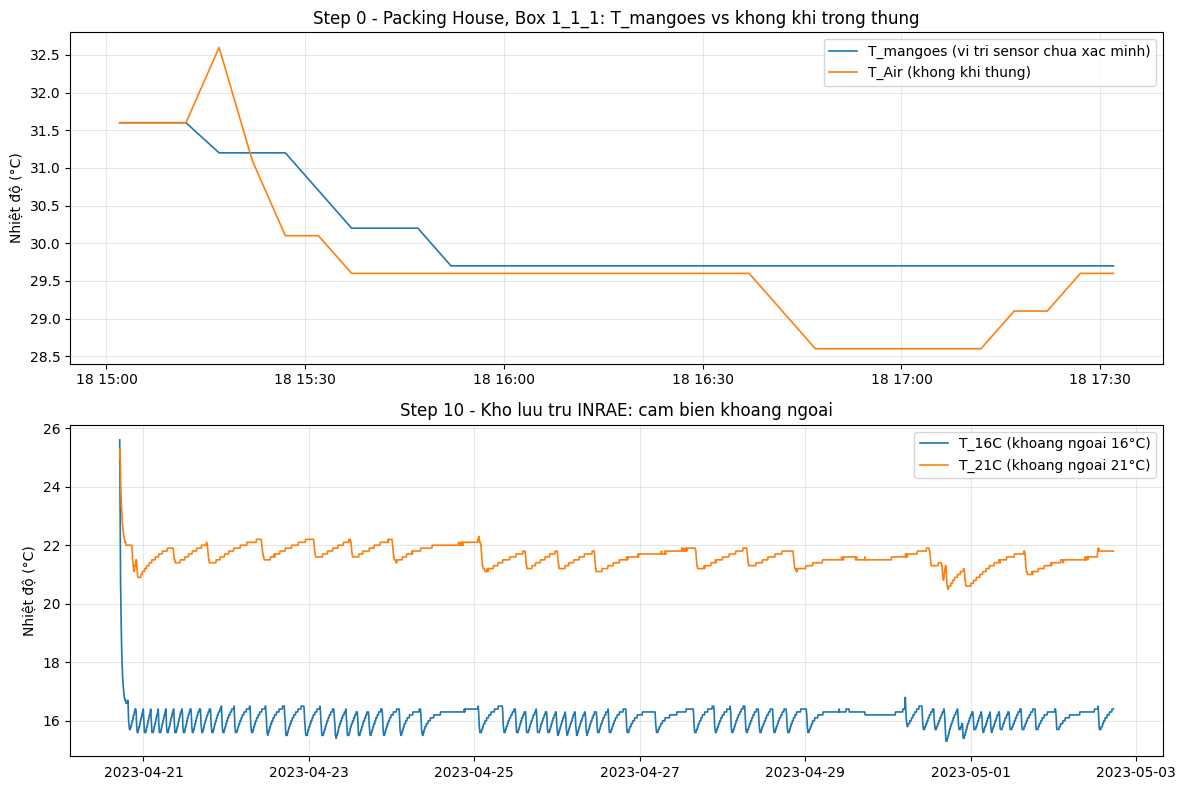

In [19]:
# ---- Doi chieu truc quan: T_qua vs T_khong_khi (box 1_1_1, Packing House) & kho ngoai ----
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

d1 = pd.read_csv(DATA_RAW / "01_src_subset_dataset_T_H/0_Packing_House_1_1_1_Temp_Hum.txt",
                 sep=r"\t|\s{2,}", engine="python")
t1 = pd.to_datetime(d1["Time"], format="%d/%m/%Y %H:%M")
axes[0].plot(t1, d1["T_mangoes"], label="T_mangoes (vi tri sensor chua xac minh)", lw=1.2)
axes[0].plot(t1, d1["T_Air"], label="T_Air (khong khi thung)", lw=1.2)
axes[0].set_title("Step 0 - Packing House, Box 1_1_1: T_mangoes vs khong khi trong thung")
axes[0].set_ylabel(u"Nhiệt độ (°C)"); axes[0].legend(); axes[0].grid(alpha=.3)

sr = pd.read_csv(DATA_RAW / "11_src_subset_dataset_SR/Storage_Room_Temp_Hum.txt",
                 sep=r"\t|\s{2,}", engine="python")
tsr = pd.to_datetime(sr["Time"], format="%d/%m/%Y %H:%M")
axes[1].plot(tsr, sr["T_16C"], label=u"T_16C (khoang ngoai 16°C)", lw=1.2)
axes[1].plot(tsr, sr["T_21C"], label=u"T_21C (khoang ngoai 21°C)", lw=1.2)
axes[1].set_title(u"Step 10 - Kho luu tru INRAE: cam bien khoang ngoai")
axes[1].set_ylabel(u"Nhiệt độ (°C)"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [20]:
# ---- Tuong quan tre giua T_Air va T_mangoes (mo ta hanh vi chuoi, KHONG suy ra vi tri sensor) ----
tm = d1["T_mangoes"].astype(float).reset_index(drop=True)
ta = d1["T_Air"].astype(float).reset_index(drop=True)
for lag in range(0, 7):  # lag tinh theo buoc mau 5 phut
    c = tm.corr(ta.shift(lag))
    print(f"lag={lag*5:2d} phut : corr(T_air -> T_mango) = {c:.3f}")

lag= 0 phut : corr(T_air -> T_mango) = 0.863
lag= 5 phut : corr(T_air -> T_mango) = 0.885
lag=10 phut : corr(T_air -> T_mango) = 0.899
lag=15 phut : corr(T_air -> T_mango) = 0.859
lag=20 phut : corr(T_air -> T_mango) = 0.776
lag=25 phut : corr(T_air -> T_mango) = 0.758
lag=30 phut : corr(T_air -> T_mango) = 0.768


## Kết luận Stage 1 & 2

1. **Kiểm kê**: toàn bộ file trong `data/raw` chia rõ 4 nhóm (sensor logs / quality / metadata-script / images); đã ánh xạ sang chuẩn `data/raw/sensor/{log_by_step, storage_room}` và `data/raw/quality/{weight,color,ph,tss}`.
2. **Data Dictionary**: các họ cột được định nghĩa đầy đủ (ý nghĩa vật lý, đơn vị °C/%/g/pH/°Brix/ngày, kiểu datetime/float), xuất ra `data/dictionary.csv`.
3. **Entity hierarchy**: Shipment (2 lô 16°C/21°C) → Pallet (4) → Box (~31, mã X_Y_Z) → Mango (1..14) → Sensor (T_mangoes / T_Air / RH_Air).
4. **Timeline**: 11 chặng Step 0→10 phục dựng được từ tiền tố file; độ dài mỗi chặng đo được từ min/max timestamp.
5. **Timestamp**: sampling chủ yếu 5 phút (log) và ~3 ngày (quality); cần localize tz theo quốc gia trước khi convert UTC; đã kiểm đếm số file có duplicate/gap/backward-jump.
6. **Sensor↔Box**: phân biệt kênh T_mangoes vs không khí thùng (T_Air/RH_Air) vs khoang ngoài (kho 16/21°C); phân tích lag cho thấy T_mangoes trễ hơn T_air (~10 phút ở Step 0). ⚠️ **Vị trí vật lý của cảm biến T_mangoes CHƯA XÁC MINH** (README chỉ ghi "mango temperature", ảnh thiết bị không cho thấy cách bố trí) — tạm ghi nhận là *"mango temperature, sensor placement unverified"*, cần cộng sự INRAE xác nhận trước khi diễn giải là nhiệt tâm hay bề mặt trong Stage 3.